In [351]:
import numpy as np
import cv2
import pandas as pd
import os
import importlib
import time
import matplotlib.pyplot as plt
import os
from skimage.exposure import rescale_intensity
from sklearn.neighbors import NearestNeighbors
import copy
import math
import ntpath

In [352]:
class point2d():
    def __init__(self, value, x=-1, y=-1, coord=None):
        if coord is not None:
            self.x = coord[0]
            self.y = coord[1]
        else:
            self.x = x 
            self.y = y
            
        self.value = value

In [353]:
class descriptor():
    def __init__(self, point, ori, desc):
        self.orientation = ori
        self.point = point
        self.desc = desc
    def setdesc(self, desc):
        self.desc = desc

In [354]:
SRCIMG = 'test2.png'

In [355]:
def compute_harris_cornor_responce(im, sigma=1.5):
    from scipy.ndimage import filters
    import numpy as np

    Ix = np.zeros(im.shape)
    filters.gaussian_filter(im, (sigma,sigma), (0,1), Ix)
    #Ix = cv2.Sobel(im, -1, 1, 0, ksize=3)
    Iy = np.zeros(im.shape)
    filters.gaussian_filter(im, (sigma,sigma), (1,0), Iy)
    #Iy = cv2.Sobel(im, -1, 0, 1, ksize=3)
    
    # compute Harris corner
    Wxx = filters.gaussian_filter(Ix**2, sigma)
    Wxy = filters.gaussian_filter(Ix*Iy, sigma)
    Wyy = filters.gaussian_filter(Iy**2, sigma)

    Wdet = Wxx * Wyy - Wxy ** 2
    Wtr = Wxx + Wyy
    return Wdet/(Wtr+1e-8)  

In [356]:
import numpy as np
from matplotlib import pyplot as plt
from PIL import Image
from scipy.ndimage import filters

In [357]:
def upscaling(src, idx):
    if idx <= 0:
        return src 
    src = upscaling(cv2.pyrUp(cv2.pyrUp(src)), idx-1)
    return src

In [358]:
orimg = cv2.imread(SRCIMG)
img = cv2.cvtColor(orimg,cv2.COLOR_BGR2GRAY)

hrpy = [] #harris response pyramid
srcs = [] #image source pyramid
src = img

In [359]:
for i in range(2):
    dst = compute_harris_cornor_responce(src)
    srcs.append(src) # store the origin size src
    hrpy.append(dst) # store the origin size response
    src = cv2.pyrDown(cv2.pyrDown(src))

/tmp/ipykernel_1206974/3239789452.py:6: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  filters.gaussian_filter(im, (sigma,sigma), (0,1), Ix)
/tmp/ipykernel_1206974/3239789452.py:9: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  filters.gaussian_filter(im, (sigma,sigma), (1,0), Iy)
/tmp/ipykernel_1206974/3239789452.py:13: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Wxx = filters.gaussian_filter(Ix**2, sigma)
/tmp/ipykernel_1206974/3239789452.py:14: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be 

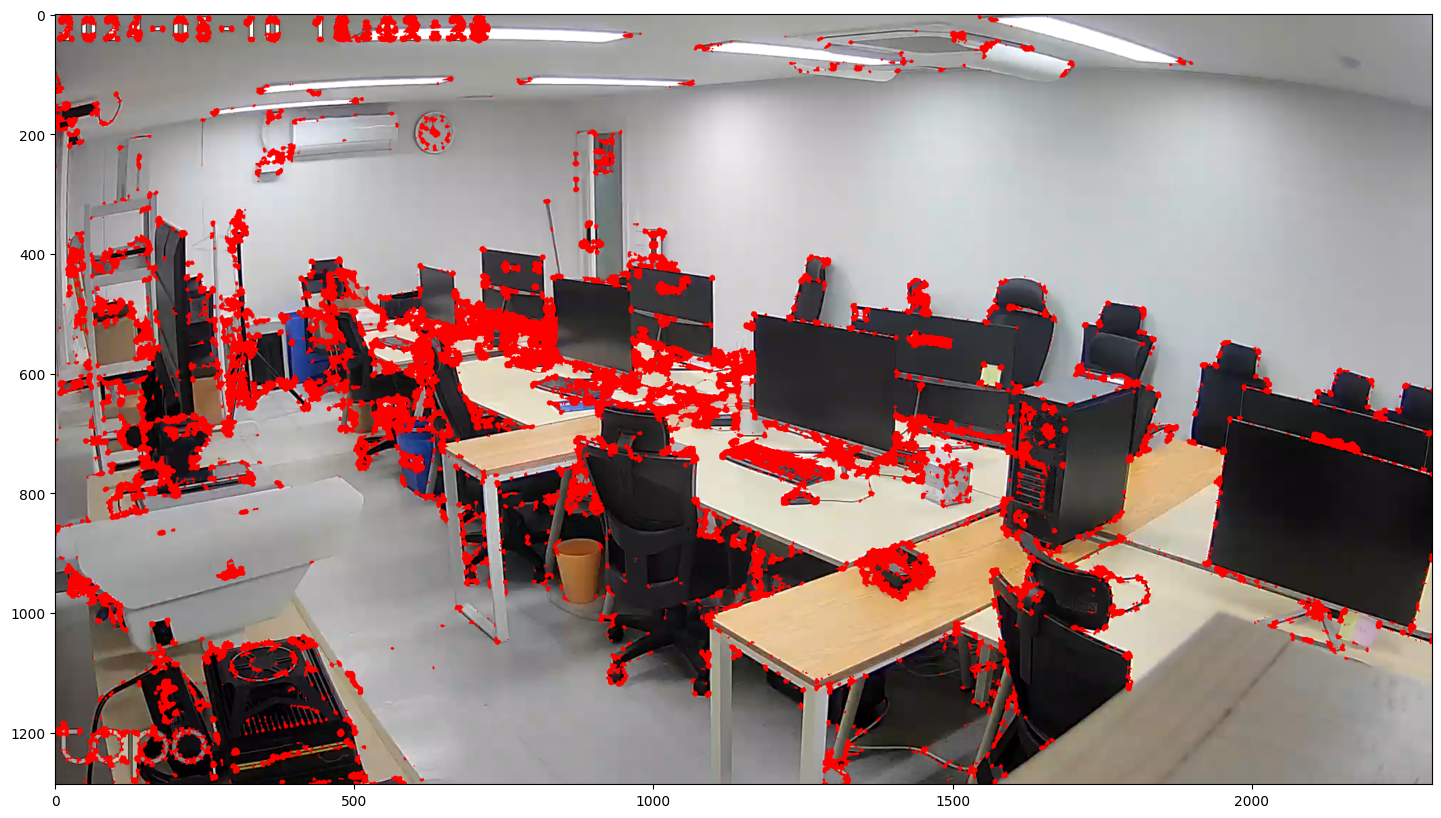

In [360]:
pltimg = copy.deepcopy(orimg)
plt.figure(figsize=(20, 10))
dst = hrpy[0]
pltimg[dst>(0.01*dst.max())]=[0, 0, 255]
plt.imshow(cv2.cvtColor(pltimg, cv2.COLOR_BGR2RGB)) 

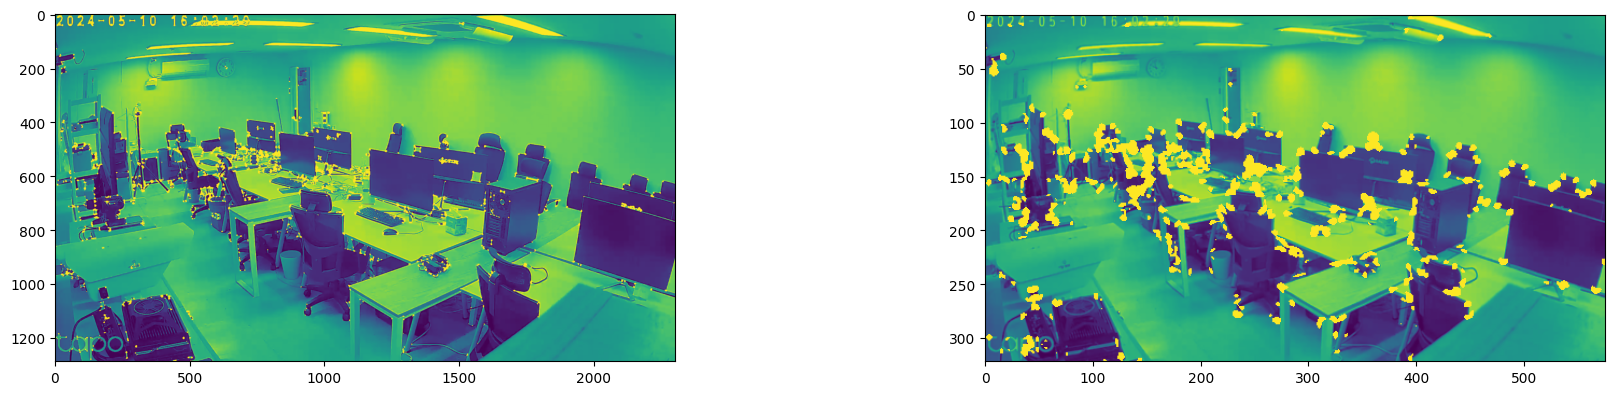

In [361]:
fig=plt.figure(figsize=(20, 10))
columns = len(hrpy)
rows = 1
for i in range(1, columns*rows+1):
    dst = hrpy[i-1]
    src = srcs[i-1]
    srcimg = copy.deepcopy(src)
    fig.subplots_adjust(wspace=0.5)
    fig.add_subplot(rows, columns, i)
    srcimg[dst>(0.1*dst.max())]=[255]
    plt.imshow(srcimg) 
    
plt.show()

In [335]:
dst.max()

228.99075210033686

In [336]:
def masksurby(src, ind, r, num):
    L0 = (ind[0] - r) if ((ind[0] - r) >= 0) else 0
    L1 = (ind[1] - r) if ((ind[1] - r) >= 0) else 0
    U0 = (ind[0] + r) if ((ind[0] + r) <= src.shape[0]) else src.shape[0]
    U1 = (ind[1] + r) if ((ind[1] + r) <= src.shape[1]) else src.shape[1]
    src[L0:U0, L1:U1] = num
    return src
def maskonly(src, ind, diameter):
    r = diameter//2
    masked = np.zeros((r, r))
    max0, max1= src.shape
    L0 = (ind[0] - r) if ((ind[0] - r) >= 0) else 0
    L1 = (ind[1] - r) if ((ind[1] - r) >= 0) else 0
    U0 = (ind[0] + r) if ((ind[0] + r) <= max0) else max0
    U1 = (ind[1] + r) if ((ind[1] + r) <= max1) else max1
    print(src.shape)
    print(ind)
    print('L1:', L1)
    print('U1:', U1)
    print('L0:', L0)
    print('U0:', U0)
    masked = src[L0:U0, L1:U1]
    return masked

In [337]:
img.shape

(1289, 2300)

In [338]:
def nonmaxsup(src, maxf=500, r=-1, maxstep=1000):
    fps = []
    if r == -1:
        r = src.shape[0]//10
   
    step = 0
    while(len(fps) <= maxf and step < maxstep and r > 1):
        r = r - 1
        fmap = copy.deepcopy(src)
        
        # mask sur
        for p in fps:
            fmap =  masksurby(fmap, (p.x, p.y), r, 0)
        maxn = 1e8
        while(maxn > src.max()*0.05):
            ind = np.unravel_index(np.argmax(fmap, axis=None), fmap.shape)
            maxn = fmap[ind]
            fmap = masksurby(fmap, ind, r, 0)
            
            fps.append(point2d(value = maxn, coord = ind)) # collect new selected feature
        step += 1
    return fps

In [339]:
hrpy[0]

array([[3.57026822e-06, 1.69309876e-05, 9.08009146e-05, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [2.12879744e-05, 9.64809271e-05, 4.71928582e-04, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.33695679e-04, 5.82723143e-04, 2.61289163e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [6.43022567e-07, 7.87503852e-06, 7.06127432e-05, ...,
        7.22426206e-04, 1.09113962e-03, 1.23960117e-03],
       [5.07355992e-07, 6.25301414e-06, 5.63886742e-05, ...,
        8.91652151e-04, 1.40437499e-03, 1.64827275e-03],
       [3.88351789e-07, 4.80753574e-06, 4.35312609e-05, ...,
        8.65866874e-04, 1.40329955e-03, 1.68332703e-03]])

In [340]:
fpspy = []
for hr in hrpy:
    fpspy.append(nonmaxsup(hr, maxf=300))

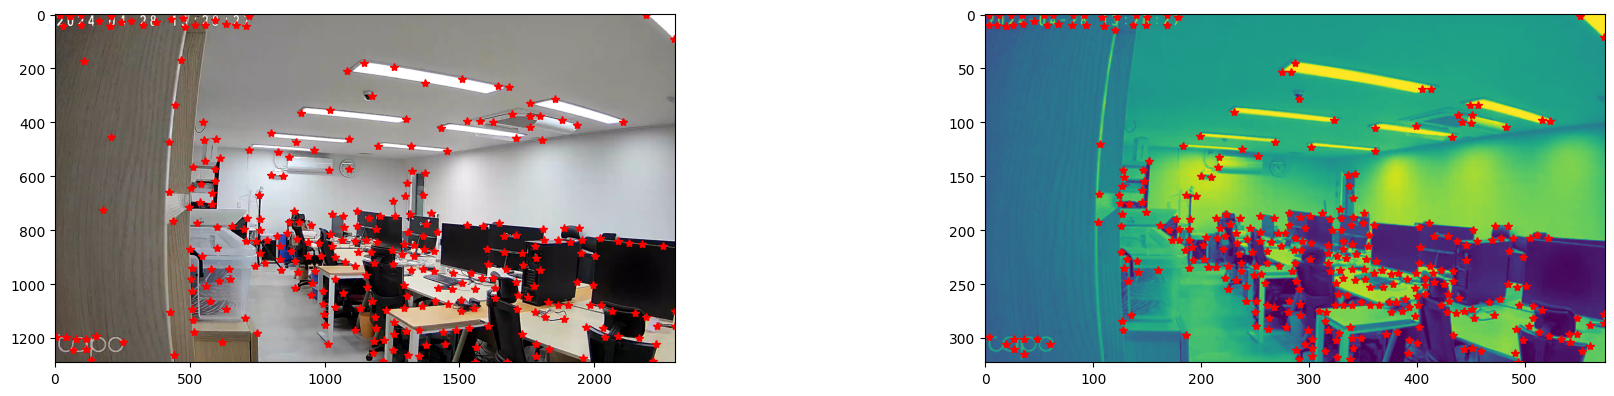

In [341]:
from matplotlib.patches import Rectangle

fig=plt.figure(figsize=(20, 10))
columns = len(hrpy)
rows = 1
for i in range(1, columns*rows+1):
    pltimg = orimg
    src = srcs[i-1]
    fig.subplots_adjust(wspace=0.5)
    fig.add_subplot(rows, columns, i)
    if(i==1):
        plt.imshow(cv2.cvtColor(pltimg, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(src)
    for p in fpspy[i-1]:
        plt.plot( p.y, p.x, 'r*')
    
plt.show()

In [342]:
descspy = []
for i in range(len(fpspy)):
    fps = fpspy[i]
    src = srcs[i]
    gx = cv2.Sobel(src, cv2.CV_32F, 1, 0, ksize=5)
    gy = cv2.Sobel(src, cv2.CV_32F, 0, 1, ksize=5)
    descs = []
    # print(i)
    for fp in fps:
        ind = (int(fp.x), int(fp.y))
        # print(ind, math.atan2(gx[ind], gy[ind]))
        rmat = cv2.getRotationMatrix2D(ind, math.atan2(gx[ind], gy[ind]), scale=1.0)
        rimg = cv2.warpAffine(src, rmat, (src.shape[1], src.shape[0]))
        masked = maskonly(rimg, ind, 40)
        if (masked.shape[1]==0):
            # print('!:', ind)
            break
        blurf = cv2.GaussianBlur(masked, ksize=(5, 5), sigmaX=1, sigmaY=1)
        resizef = cv2.resize(blurf, (8, 8)) # 8*8
        normf = (resizef-np.mean(resizef))/np.std(resizef) 
        descs.append(descriptor(fp, (gx[ind], gy[ind]), normf))
    descspy.append(descs)

(1289, 2300)
(815, 1020)
L1: 1000
U1: 1040
L0: 795
U0: 835
(1289, 2300)
(669, 755)
L1: 735
U1: 775
L0: 649
U0: 689
(1289, 2300)
(994, 1936)
L1: 1916
U1: 1956
L0: 974
U0: 1014
(1289, 2300)
(927, 1255)
L1: 1235
U1: 1275
L0: 907
U0: 947
(1289, 2300)
(807, 1418)
L1: 1398
U1: 1438
L0: 787
U0: 827
(1289, 2300)
(991, 1709)
L1: 1689
U1: 1729
L0: 971
U0: 1011
(1289, 2300)
(41, 28)
L1: 8
U1: 48
L0: 21
U0: 61
(1289, 2300)
(1194, 2087)
L1: 2067
U1: 2107
L0: 1174
U0: 1214
(1289, 2300)
(1088, 1555)
L1: 1535
U1: 1575
L0: 1068
U0: 1108
(1289, 2300)
(24, 164)
L1: 144
U1: 184
L0: 4
U0: 44
(1289, 2300)
(839, 709)
L1: 689
U1: 729
L0: 819
U0: 859
(1289, 2300)
(951, 966)
L1: 946
U1: 986
L0: 931
U0: 971
(1289, 2300)
(858, 1779)
L1: 1759
U1: 1799
L0: 838
U0: 878
(1289, 2300)
(837, 1956)
L1: 1936
U1: 1976
L0: 817
U0: 857
(1289, 2300)
(38, 520)
L1: 500
U1: 540
L0: 18
U0: 58
(1289, 2300)
(774, 1646)
L1: 1626
U1: 1666
L0: 754
U0: 794
(1289, 2300)
(746, 1205)
L1: 1185
U1: 1225
L0: 726
U0: 766
(1289, 2300)
(701, 58

/tmp/ipykernel_1206974/3614666100.py:20: RuntimeWarning: invalid value encountered in divide
  normf = (resizef-np.mean(resizef))/np.std(resizef)


(1289, 2300)
(939, 507)
L1: 487
U1: 527
L0: 919
U0: 959
(1289, 2300)
(995, 953)
L1: 933
U1: 973
L0: 975
U0: 1015
(1289, 2300)
(796, 702)
L1: 682
U1: 722
L0: 776
U0: 816
(1289, 2300)
(597, 802)
L1: 782
U1: 822
L0: 577
U0: 617
(1289, 2300)
(1072, 993)
L1: 973
U1: 1013
L0: 1052
U0: 1092
(1289, 2300)
(844, 1910)
L1: 1890
U1: 1930
L0: 824
U0: 864
(1289, 2300)
(1122, 2192)
L1: 2172
U1: 2212
L0: 1102
U0: 1142
(1289, 2300)
(881, 1124)
L1: 1104
U1: 1144
L0: 861
U0: 901
(1289, 2300)
(792, 1887)
L1: 1867
U1: 1907
L0: 772
U0: 812
(1289, 2300)
(270, 1684)
L1: 1664
U1: 1704
L0: 250
U0: 290
(1289, 2300)
(990, 608)
L1: 588
U1: 628
L0: 970
U0: 1010
(1289, 2300)
(1059, 1505)
L1: 1485
U1: 1525
L0: 1039
U0: 1079
(1289, 2300)
(838, 1154)
L1: 1134
U1: 1174
L0: 818
U0: 858
(1289, 2300)
(695, 539)
L1: 519
U1: 559
L0: 675
U0: 715
(1289, 2300)
(778, 1376)
L1: 1356
U1: 1396
L0: 758
U0: 798
(1289, 2300)
(1045, 1307)
L1: 1287
U1: 1327
L0: 1025
U0: 1065
(1289, 2300)
(1134, 512)
L1: 492
U1: 532
L0: 1114
U0: 1154
(12

In [348]:
descspy

[[], []]

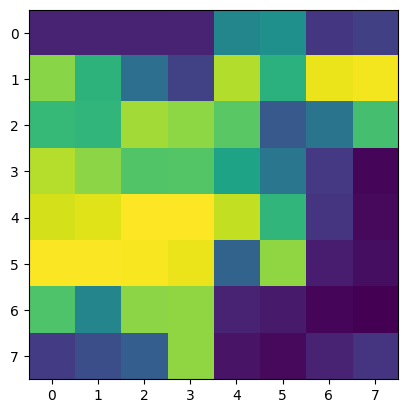

In [344]:
plt.imshow(descs[0].desc)

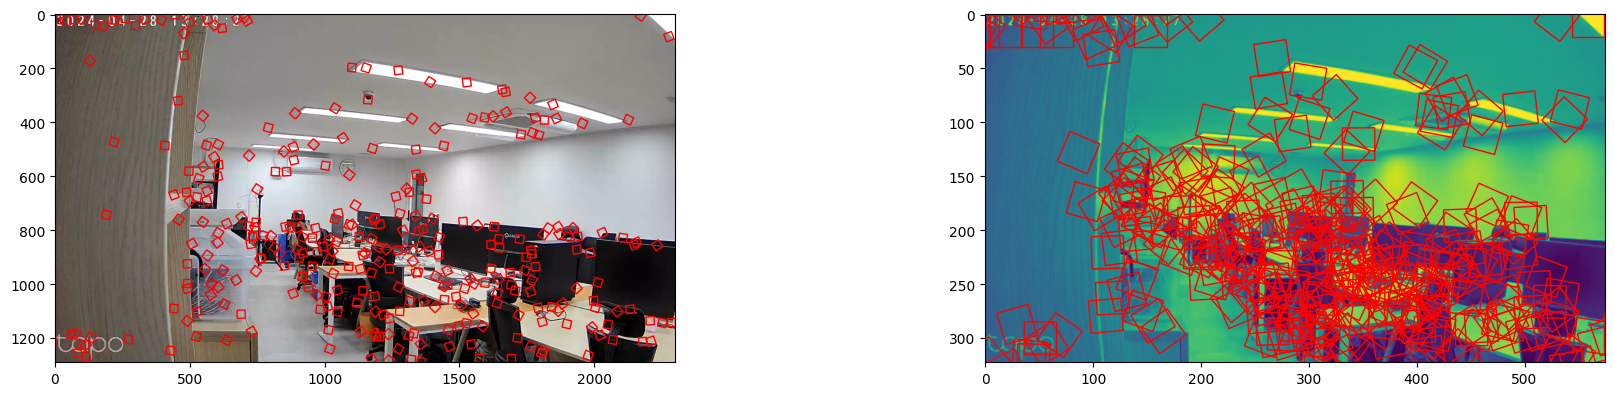

In [345]:
from matplotlib.patches import Rectangle

fig=plt.figure(figsize=(20, 10))
columns = len(hrpy)
rows = 1
for i in range(1, columns*rows+1):
    pltimg = orimg
    src = srcs[i-1]
    fig.subplots_adjust(wspace=0.5)
    fig.add_subplot(rows, columns, i)
    if(i==1):
        plt.imshow(cv2.cvtColor(pltimg, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(src)
    ax = plt.gca()
    for d in descspy[i-1]:
        rect = Rectangle( (d.point.y, d.point.x), 30, 30, angle=math.degrees(math.atan2(d.orientation[0], d.orientation[1])), linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(rect)
    
plt.show()

In [370]:
meta_path = 'meta.txt'
n_imgs = 25
n_pys = 2

voting_threshold = 5
rt_threshold = 0.7
with open(meta_path) as f:
    content = f.readlines()
content = [x.strip() for x in content] 

content

['test1.png',
 '1292, 2300',
 '',
 '4 0 1511.5',
 '0 4 2015.5',
 '0 0 1',
 '',
 '-0.758347 0.0317341 -0.651078',
 '-0.0210253 -0.999485 -0.0242265',
 '-0.651512 -0.00468303 0.758624',
 '',
 '764.1348',
 '',
 'test2.png',
 '1292, 2300',
 '',
 '4 0 1511.5',
 '0 4 2015.5',
 '0 0 1',
 '',
 '-0.758347 0.0317341 -0.651078',
 '-0.0210253 -0.999485 -0.0242265',
 '-0.651512 -0.00468303 0.758624',
 '',
 '764.17',
 '']

In [371]:
ii = 0
metas = []
func = None
for line in content:
    if ii == 0:
        if func is None:
            func = ntpath.basename if '\\' in line else os.path.basename
        meta = {'filename':func(line)}
    elif ii== 11:
        meta['f'] = float(line)
    elif ii == 12:
        ii = 0
        metas.append(meta)
        print(meta)
        continue
    ii+=1
metas

{'filename': 'test1.png', 'f': 764.1348}
{'filename': 'test2.png', 'f': 764.17}


[{'filename': 'test1.png', 'f': 764.1348},
 {'filename': 'test2.png', 'f': 764.17}]

In [384]:
n_imgs = len(metas) if n_imgs > len(metas) else n_imgs
imgsize = (1920, 1080) 

In [385]:
def cylindrical_projection(img, focal_length):
    if(len(img.shape)>2):
        height, width, _ = img.shape
    else:
        height, width = img.shape
    cylinder_proj = np.zeros(shape=img.shape, dtype=np.uint8)
    
    for y in range(-int(height/2), int(height/2)):
        for x in range(-int(width/2), int(width/2)):
            cylinder_x = focal_length*math.atan(x/focal_length)
            cylinder_y = focal_length*y/math.sqrt(x**2+focal_length**2)
            
            cylinder_x = round(cylinder_x + width/2)
            cylinder_y = round(cylinder_y + height/2)
            if cylinder_x >= 0 and cylinder_x < width and cylinder_y >= 0 and cylinder_y < height:
                cylinder_proj[cylinder_y][cylinder_x] = img[y+int(height/2)][x+int(width/2)]
    
    if(len(img.shape)>2):
        _, thresh = cv2.threshold(cv2.cvtColor(cylinder_proj, cv2.COLOR_BGR2GRAY), 1, 255, cv2.THRESH_BINARY)
    else:
        _, thresh = cv2.threshold(cylinder_proj, 1, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    x, y, w, h = cv2.boundingRect(contours[0])
        
    return cylinder_proj[y:y+h, x:x+w]


In [402]:

prjimgs = []
orimgs = []
fs = []
for m in metas[:n_imgs]:
    # orimg = cv2.resize(cv2.imread(os.path.join(m['filename'])), imgsize)
    orimg = cv2.imread(os.path.join(m['filename']))
    prjimg= cylindrical_projection(orimg, m['f'])
    prjimgs.append(prjimg)
    orimgs.append(orimg)
    fs.append(m['f'])

In [403]:
n_imgs

2

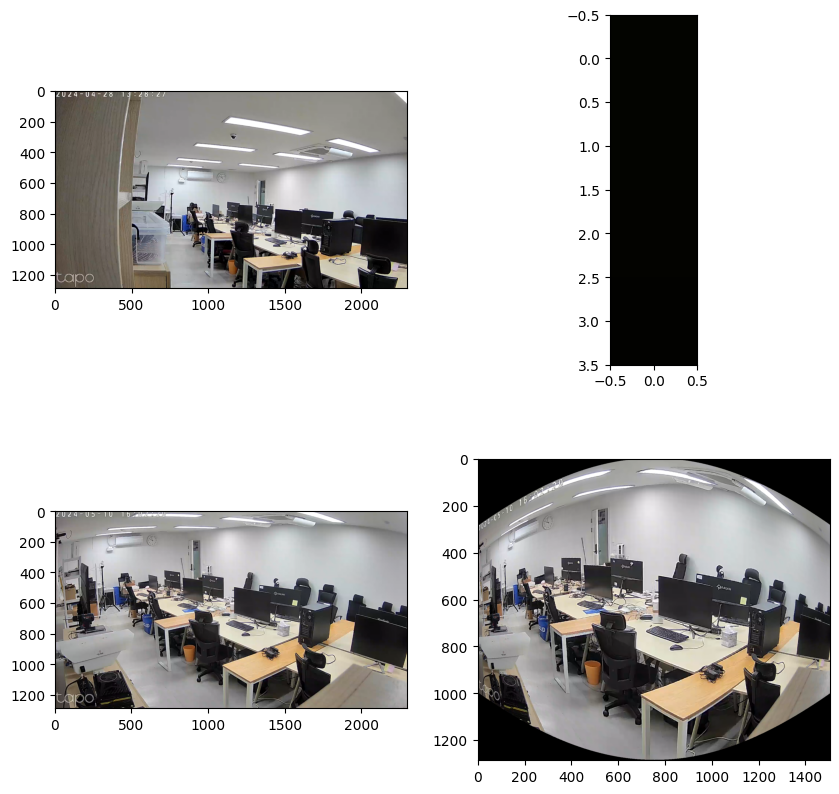

In [404]:
columns = 2
rows = len(orimgs)
fig=plt.figure(figsize=(columns*5, rows*5))

for i in range(1, rows+1):
    orimg = orimgs[i-1]
    prjimg = prjimgs[i-1]
    fig.subplots_adjust(wspace=0.2)
    fig.add_subplot(rows, columns, i*2-1)
    plt.imshow(cv2.cvtColor(orimg, cv2.COLOR_BGR2RGB)) 
    fig.subplots_adjust(wspace=0.2)
    fig.add_subplot(rows, columns, i*2)
    plt.imshow(cv2.cvtColor(prjimg, cv2.COLOR_BGR2RGB)) 

In [399]:
len(orimgs)

2

In [400]:
def msop(orimg, maxfeat=300, n_pym = 2, prj=False, focal_length=0):
    img = cv2.cvtColor(orimg,cv2.COLOR_BGR2GRAY)
    plt.imshow(cv2.cvtColor(orimg, cv2.COLOR_BGR2RGB))
    _hrpy = [] 
    _srcs = [] 
    _src = img
    for i in tqdm(range(n_pym)):
        dst = compute_harris_cornor_responce(_src)
        _srcs.append(_src) 
        _hrpy.append(dst) 
        _src = cv2.pyrDown(cv2.pyrDown(_src))
    if (prj):
        if(focal_length==0):
            return None
        for i in range(n_pym):
            _hrpy[i] =  cylindrical_projection(_hrpy[i], focal_length)
            _srcs[i] =  cylindrical_projection(_srcs[i], focal_length)
        
    _fpspy = []
    for hr in _hrpy:
        _fpspy.append(nonmaxsup(hr, maxf=maxfeat))
    descspy = []

    fig=plt.figure(figsize=(20, 10))
    columns = len(_hrpy)
    rows = 1
    for i in range(1, columns*rows+1):
        pltimg = orimg
        _src = _srcs[i-1]
        fig.subplots_adjust(wspace=0.5)
        fig.add_subplot(rows, columns, i)
        if(i==1):
            plt.imshow(cv2.cvtColor(pltimg, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(_src)
        for p in fpspy[i-1]:
            plt.plot( p.y, p.x, 'r*')
        
    plt.show()
    print(_fpspy)
    for i in range(n_pym):
        fps = _fpspy[i]
        _src = _srcs[i]
        gx = cv2.Sobel(_src, cv2.CV_32F, 1, 0, ksize=5)
        gy = cv2.Sobel(_src, cv2.CV_32F, 0, 1, ksize=5)
        descs = []
        for fp in fps:
            ind = (int(fp.x), int(fp.y))
            rmat = cv2.getRotationMatrix2D(ind, math.atan2(gx[ind], gy[ind]), scale=1.0)
            rimg = cv2.warpAffine(_src, rmat, (_src.shape[1], _src.shape[0]))
            masked = maskonly(rimg, ind, 40)
            if (masked.shape[1]==0):
                break
            blurf = cv2.GaussianBlur(masked, ksize=(5, 5), sigmaX=1, sigmaY=1)
            resizef = cv2.resize(blurf, (8, 8)) # 8*8
            normf = (resizef-np.mean(resizef))/(np.std(resizef) + 1e-8)
            descs.append(descriptor(fp, (gx[ind], gy[ind]), normf))
            print(descs)
        descspy.append(descs)
        
        
    
    return descspy, srcs

In [401]:
descspys = []
imgpys = []
for i in tqdm(range(n_imgs)):
    descspy, imgpy = msop(orimgs[i], prj=True, focal_length=fs[i], n_pym = n_pys)
    descspys.append(descspy) # put original img into msop function
    imgpys.append(imgpy)


 0%|          | 0/2 [00:00<?, ?it/s]

error: OpenCV(4.10.0) /io/opencv/modules/imgproc/src/color.simd_helpers.hpp:92: error: (-2:Unspecified error) in function 'cv::impl::{anonymous}::CvtHelper<VScn, VDcn, VDepth, sizePolicy>::CvtHelper(cv::InputArray, cv::OutputArray, int) [with VScn = cv::impl::{anonymous}::Set<3, 4>; VDcn = cv::impl::{anonymous}::Set<1>; VDepth = cv::impl::{anonymous}::Set<0, 2, 5>; cv::impl::{anonymous}::SizePolicy sizePolicy = cv::impl::<unnamed>::NONE; cv::InputArray = const cv::_InputArray&; cv::OutputArray = const cv::_OutputArray&]'
> Invalid number of channels in input image:
>     'VScn::contains(scn)'
> where
>     'scn' is 1


In [393]:
descspys

[[[], []], [[], []]]

In [394]:
len(descspy)

2

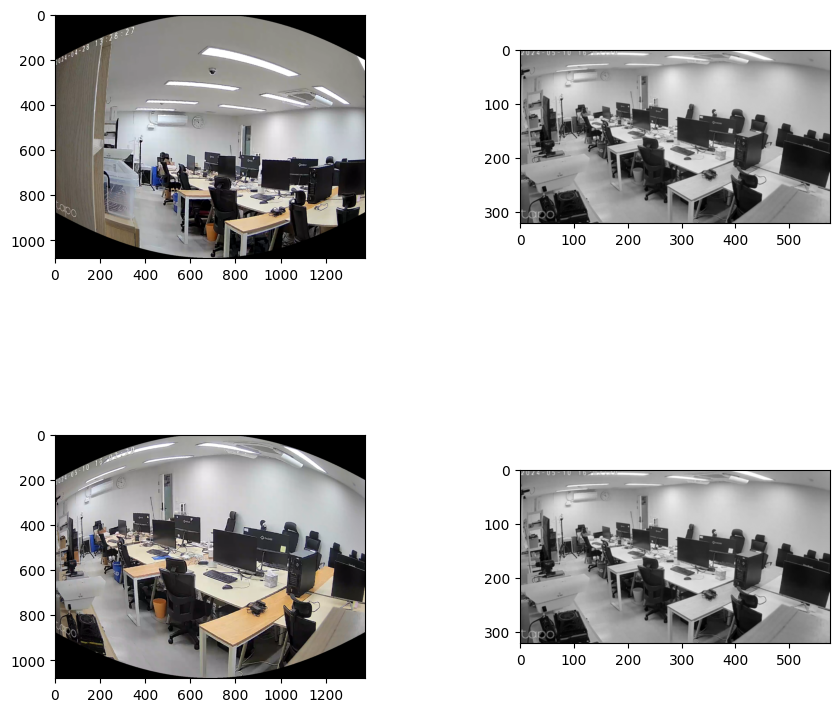

In [395]:
from matplotlib.patches import Rectangle


columns = n_pys
rows = len(descspys)
fig=plt.figure(figsize=(columns*5, rows*5))
for i in range(1, rows+1):
    pltimg = prjimgs[i-1]
    
    fig.subplots_adjust(wspace=0.5)
    fig.add_subplot(rows, columns, (i-1)*n_pys+1)
   
    plt.imshow(cv2.cvtColor(pltimg, cv2.COLOR_BGR2RGB))
    for d in descspys[i-1][0]:
        plt.plot(d.point.y, d.point.x, 'r.')
    
    for p in range(1, n_pys):
        fig.subplots_adjust(wspace=0.5)
        fig.add_subplot(rows, columns, (i-1)*n_pys+1+p)
        plt.imshow(imgpys[i-1][p],  cmap='gray')
        for d in descspys[i-1][p]:
            plt.plot(d.point.y, d.point.x, 'r.')
    
plt.show()

In [307]:
def descspy2arr(descspy):
    darrpy = []
    for descs in descspy:
        numd = len(descs)
        dim = descs[0].desc.flatten().shape[0]
        darr = np.zeros((numd, dim))
        for d in range(numd):
            darr[d, :] = descs[d].desc.flatten().astype('float64')
        darrpy.append(darr)
    return darrpy

In [308]:
def feature_matching(descpyA, descpyB, rtThreshold = 0.7):
    """
        rtThreshold: Threshold for David Lowe’s ratio test when picking features. Lower is stricter.
    """
    a2bpairspy = []
    for py in range(len(descpyA)):
        darrA = descspy2arr(descpyA)
        darrB = descspy2arr(descpyB)

        X = darrB[py] # 0 stage of pyramimd B
        Y = darrA[py]

        #print('X:', X)
        nbrs = NearestNeighbors(n_neighbors=2, algorithm='ball_tree').fit(X)
        distances, indices = nbrs.kneighbors(Y)

        a2bpairs = []
        #print('indices:', indices)
        for ind in range(len(distances)):
            ds = distances[ind]
            # David Lowe’s ratio test
            if (ds[0] < ds[1] * rtThreshold):
                a2bpairs.append((ind, indices[ind][0]))
        
        a2bpairspy.append(a2bpairs)
    #print(a2bpairs)
    return a2bpairspy

In [310]:
descspys

[[[], []], [[], []]]

In [309]:
pairsallpys = []
for i in range(len(descspys) - 1):  
    a2bpairspy = feature_matching(descspys[i], descspys[i+1], rtThreshold = 0.7)
    pairsallpys.append(a2bpairspy)

IndexError: list index out of range